룰 베이스라인: 단일 룰과 조합 룰의 검출률, 오탐 건수, 연령대별 오탐률 측정 <p>
임계값은 train에서만 정하고 valid에는 적용만 함, test는 03_model에서 최종 1회 사용

In [13]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

In [3]:
base = pd.read_parquet("../data/processed/base.parquet")

In [4]:
train = base[base["month"] <= 4]
valid = base[base["month"] == 5]
test = base[base["month"] >= 6]

In [14]:
train.groupby("proposed_credit_limit")["fraud_bool"].agg(["size", "mean"])

,size,mean
proposed_credit_limit,,
190.0,81,0.000000
200.0,413190,0.006508
210.0,487,0.000000
490.0,336,0.008929
500.0,85149,0.009172
510.0,5276,0.004170
990.0,3572,0.012598
1000.0,48710,0.009649
1500.0,114860,0.019537


In [15]:
rules = {
    "고액 한도": lambda d: d["proposed_credit_limit"] >= 1900,
    "주거 BA": lambda d: d["housing_status"] == "BA",
    "windows": lambda d: d["device_os"] == "windows",
    "이름메일 유사도 낮음": lambda d: d["name_email_similarity"] < 0.18,
    "생년월일 메일 적음": lambda d: d["date_of_birth_distinct_emails_4w"] <= 4,
    "지점 방문 적음": lambda d: d["bank_branch_count_8w"] <= 1,
}


def eval_rule(df, flag):
    y = df["fraud_bool"] == 1
    old = df["customer_age"] >= 50
    tp = (flag & y).sum()
    fp = (flag & ~y).sum()
    return pd.Series({
        "flag_rate": flag.mean(),
        "precision": tp / flag.sum(),
        "recall": tp / y.sum(),
        "lift": (tp / flag.sum()) / y.mean(),
        "fp_per_1000": fp / len(df) * 1000,
        "fpr_50plus": (flag & ~y & old).sum() / (~y & old).sum(),
        "fpr_under50": (flag & ~y & ~old).sum() / (~y & ~old).sum(),
    })

In [16]:
train_single = pd.DataFrame({k: eval_rule(train, f(train)) for k, f in rules.items()}).T
train_single.round(4)

,flag_rate,precision,recall,lift,fp_per_1000,fpr_50plus,fpr_under50
고액 한도,0.0059,0.1213,0.0721,12.1648,5.2082,0.0096,0.0043
주거 BA,0.1634,0.0342,0.5605,3.4298,157.8369,0.2836,0.1307
windows,0.2700,0.0225,0.6077,2.2508,263.9366,0.3673,0.2433
이름메일 유사도 낮음,0.2006,0.0181,0.3631,1.8098,196.9864,0.2295,0.1919
생년월일 메일 적음,0.1369,0.0221,0.3028,2.2128,133.8294,0.4018,0.0735
지점 방문 적음,0.2950,0.0153,0.4537,1.5379,290.4941,0.2791,0.2967


In [17]:
hits = pd.concat({k: f(train) for k, f in rules.items()}, axis=1).sum(axis=1)
train_combo = pd.DataFrame({f"{n}개 이상": eval_rule(train, hits >= n) for n in [1, 2, 3]}).T
train_combo.round(4)

,flag_rate,precision,recall,lift,fp_per_1000,fpr_50plus,fpr_under50
1개 이상,0.6943,0.0136,0.9451,1.3613,684.8472,0.8416,0.6571
2개 이상,0.2845,0.0267,0.7623,2.6791,276.9356,0.4967,0.2295
3개 이상,0.0773,0.0580,0.4500,5.8188,72.8466,0.1871,0.0473


In [18]:
valid_single = pd.DataFrame({k: eval_rule(valid, f(valid)) for k, f in rules.items()}).T
valid_single.round(4)

,flag_rate,precision,recall,lift,fp_per_1000,fpr_50plus,fpr_under50
고액 한도,0.0067,0.1409,0.0794,11.9137,5.7240,0.0086,0.0052
주거 BA,0.1622,0.0410,0.5620,3.4653,155.5358,0.2549,0.1372
windows,0.2556,0.0265,0.5734,2.2434,248.7953,0.3433,0.2328
이름메일 유사도 낮음,0.1812,0.0214,0.3274,1.8073,177.3003,0.2008,0.1750
생년월일 메일 적음,0.1551,0.0207,0.2714,1.7499,151.9070,0.3922,0.1043
지점 방문 적음,0.2782,0.0189,0.4444,1.5970,272.9901,0.2620,0.2792


In [19]:
hits_v = pd.concat({k: f(valid) for k, f in rules.items()}, axis=1).sum(axis=1)
valid_combo = pd.DataFrame({f"{n}개 이상": eval_rule(valid, hits_v >= n) for n in [1, 2, 3]}).T
valid_combo.round(4)

,flag_rate,precision,recall,lift,fp_per_1000,fpr_50plus,fpr_under50
1개 이상,0.6821,0.0163,0.9405,1.3788,670.9687,0.8196,0.6498
2개 이상,0.2741,0.0313,0.7264,2.6499,265.5481,0.4528,0.2306
3개 이상,0.0698,0.0706,0.4167,5.9737,64.8324,0.1557,0.0469


In [20]:
cols = ["precision", "recall", "lift", "fp_per_1000"]
pd.concat({"train": train_single[cols], "valid": valid_single[cols]}, axis=1).round(4)

train                                  valid                   \
            precision  recall     lift fp_per_1000 precision  recall     lift   
고액 한도          0.1213  0.0721  12.1648      5.2082    0.1409  0.0794  11.9137   
주거 BA          0.0342  0.5605   3.4298    157.8369    0.0410  0.5620   3.4653   
windows        0.0225  0.6077   2.2508    263.9366    0.0265  0.5734   2.2434   
이름메일 유사도 낮음    0.0181  0.3631   1.8098    196.9864    0.0214  0.3274   1.8073   
생년월일 메일 적음     0.0221  0.3028   2.2128    133.8294    0.0207  0.2714   1.7499   
지점 방문 적음       0.0153  0.4537   1.5379    290.4941    0.0189  0.4444   1.5970   

                         
            fp_per_1000  
고액 한도            5.7240  
주거 BA          155.5358  
windows        248.7953  
이름메일 유사도 낮음    177.3003  
생년월일 메일 적음     151.9070  
지점 방문 적음       272.9901

In [21]:
pd.concat({"train": train_combo[cols], "valid": valid_combo[cols]}, axis=1).round(4)

train                                 valid                  \
      precision  recall    lift fp_per_1000 precision  recall    lift   
1개 이상    0.0136  0.9451  1.3613    684.8472    0.0163  0.9405  1.3788   
2개 이상    0.0267  0.7623  2.6791    276.9356    0.0313  0.7264  2.6499   
3개 이상    0.0580  0.4500  5.8188     72.8466    0.0706  0.4167  5.9737   

                   
      fp_per_1000  
1개 이상    670.9687  
2개 이상    265.5481  
3개 이상     64.8324

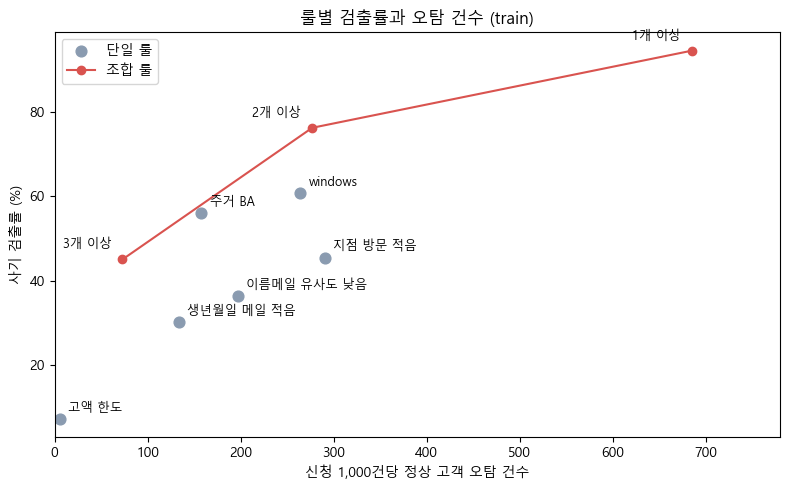

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(train_single["fp_per_1000"], train_single["recall"] * 100,
           color="#8a9bb0", s=60, label="단일 룰")
for name, row in train_single.iterrows():
    ax.annotate(name, (row["fp_per_1000"], row["recall"] * 100),
                textcoords="offset points", xytext=(6, 5), fontsize=9)

ax.plot(train_combo["fp_per_1000"], train_combo["recall"] * 100,
        color="#d9534f", marker="o", label="조합 룰")
for name, row in train_combo.iterrows():
    ax.annotate(name, (row["fp_per_1000"], row["recall"] * 100),
                textcoords="offset points", xytext=(-8, 8), fontsize=9, ha="right")

ax.set_xlim(0, 780)
ax.set_xlabel("신청 1,000건당 정상 고객 오탐 건수")
ax.set_ylabel("사기 검출률 (%)")
ax.set_title("룰별 검출률과 오탐 건수 (train)")
ax.legend()
plt.tight_layout()
plt.savefig("../images/rule_tradeoff.png", dpi=150)
plt.show()

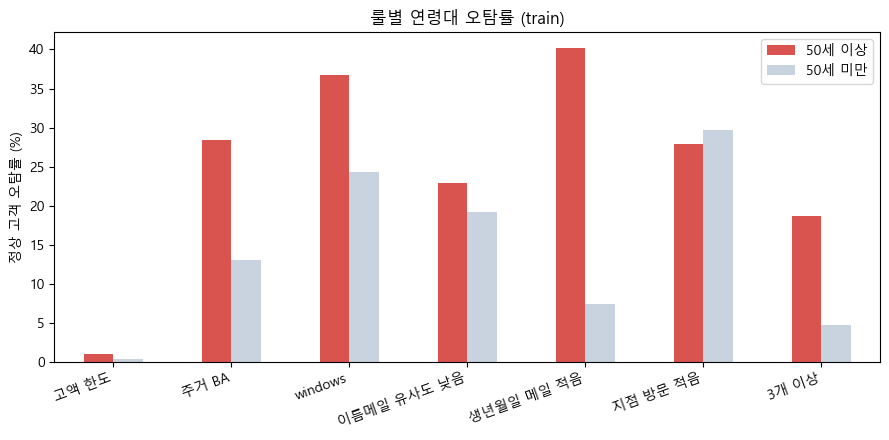

In [23]:
age_fpr = pd.concat([train_single, train_combo.loc[["3개 이상"]]])
age_fpr = age_fpr[["fpr_50plus", "fpr_under50"]] * 100
age_fpr.columns = ["50세 이상", "50세 미만"]

ax = age_fpr.plot(kind="bar", figsize=(9, 4.5), color=["#d9534f", "#c9d3df"])
ax.set_xlabel("")
ax.set_ylabel("정상 고객 오탐률 (%)")
ax.set_title("룰별 연령대 오탐률 (train)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("../images/rule_age_fpr.png", dpi=150)
plt.show()

생년월일 매일 적은 - 50세 이상 약 40%, 미만 약 7% 크게 갈린다. 

지점 방문 적음 - 연령 편중이 없는 유일한 룰. lift가 가장 낮아 공정하지만 약한 룰로 정리됨 

3개 이상 조합 - 50세 이상 약 19%, 미만 약 5%로 4배 차이 남

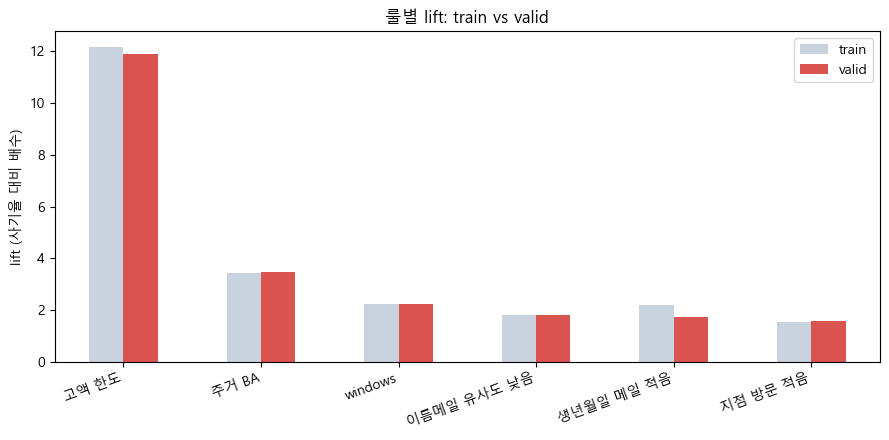

In [24]:
lift_cmp = pd.concat({"train": train_single["lift"], "valid": valid_single["lift"]}, axis=1)

ax = lift_cmp.plot(kind="bar", figsize=(9, 4.5), color=["#c9d3df", "#d9534f"])
ax.set_xlabel("")
ax.set_ylabel("lift (사기율 대비 배수)")
ax.set_title("룰별 lift: train vs valid")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("../images/rule_lift_train_valid.png", dpi=150)
plt.show()

생년월일 메일 적음 부분만 낮아졌다. 나머지는 거의 같다. 